# M5.2 · 盘口撮合与流动性约束

> 真实订单要落到限价订单簿上：市价单逐档吃单、可能只部分成交；涨跌停、停牌、参与率都会阻断交易，大单还会产生市场冲击。

## 一、订单簿与约束机制

1. **限价订单簿（LOB）**：bid/ask 各价格档位的挂单量，含中间价、买卖价差；
2. **市价单吃单**：按价格优先逐档成交，流动性不足时残留未成交；
3. **涨跌停/停牌**：涨停买不进、跌停卖不出，停牌无行情拒单；
4. **参与率约束**：单笔不超过市场成交量的一定比例，超出部分截断；
5. **市场冲击**：线性模型 $\text{impact}=k\cdot q/ADV$，大单推高成交价。

## 二、订单簿撮合

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
from bt_lab2 import matching as mt
ob = mt.OrderBook()
ob.add_limit('SELL', 100.0, 50); ob.add_limit('SELL', 100.1, 80)
ob.add_limit('BUY', 99.9, 60); ob.add_limit('BUY', 99.8, 100)
fills, unfilled = ob.market_order('BUY', 100)
print('市价买100: 成交档=%s 未成交=%d' % (fills, unfilled))
print('中间价=%.3f 价差=%.2f' % (ob.mid(), ob.spread()))
fills2, unf2 = ob.market_order('BUY', 200)
print('市价买200（流动性不足）: 未成交=%d' % unf2)

市价买100: 成交档=[(100.0, 50), (100.1, 50)] 未成交=0
中间价=99.950 价差=0.10
市价买200（流动性不足）: 未成交=70


## 三、流动性约束与冲击

In [2]:
bar = {'open': 10.0, 'high': 10.2, 'low': 9.8, 'close': 10.1, 'volume': 10000}
ex = mt.execute_with_constraints('BUY', 3000, bar, 9.5, participation=0.1)
print('参与率约束: %s 成交=%d 冲击=%.5f' % (ex['status'], ex['filled_qty'], ex['impact']))
print('停牌拒单=%s' % mt.execute_with_constraints('BUY', 100, {**bar, 'volume': 0}, 9.5)['reason'])
print('涨停拒单=%s' % mt.execute_with_constraints('BUY', 100, bar, 9.0)['reason'])
print('跌停拒单=%s' % mt.execute_with_constraints('SELL', 100, bar, 11.1)['reason'])

参与率约束: PARTIAL 成交=1000 冲击=0.01000
停牌拒单=HALTED
涨停拒单=LIMIT_UP
跌停拒单=LIMIT_DOWN


## 四、可视化

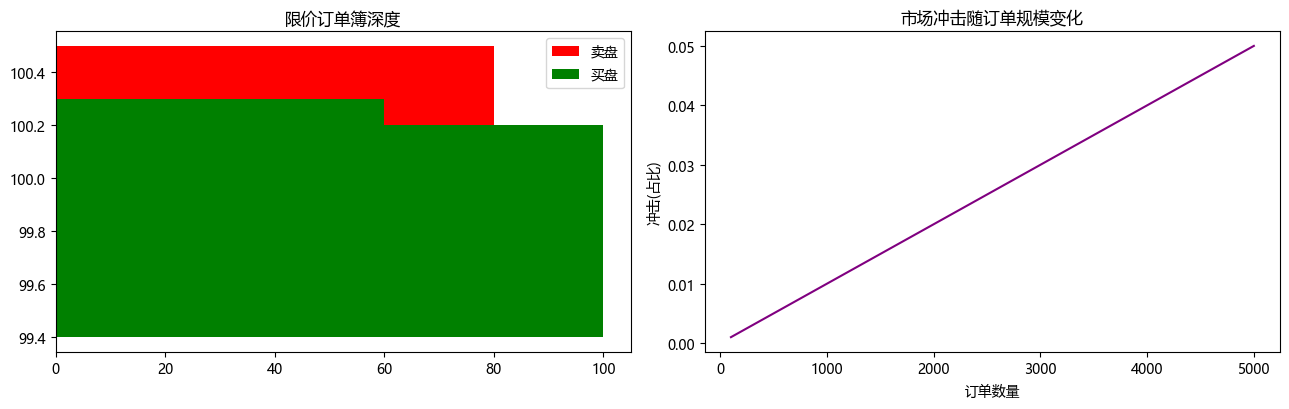

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ask_px = sorted(ob.asks); bid_px = sorted(ob.bids, reverse=True)
ax[0].barh(ask_px, [ob.asks[p] for p in ask_px], color='red', label='卖盘')
ax[0].barh(bid_px, [ob.bids[p] for p in bid_px], color='green', label='买盘')
ax[0].set_title('限价订单簿深度'); ax[0].legend()
q_grid = np.linspace(100, 5000, 20)
ax[1].plot(q_grid, [mt.market_impact(q, 10000, 0.1) for q in q_grid], color='purple')
ax[1].set_title('市场冲击随订单规模变化'); ax[1].set_xlabel('订单数量'); ax[1].set_ylabel('冲击(占比)')
plt.tight_layout(); plt.show()

## 五、面试要点

- **买卖价差反映什么？** 即时流动性成本与做市商补偿；价差越宽，立即成交越贵。
- **市价单为何会部分成交？** 对手盘挂单总量有限，逐档吃完仍不足时残留未成交，需要拆单或等待。
- **参与率约束的意义？** 防止单笔订单占市场成交比例过高而造成显著冲击，VWAP/POV 即据此拆单。
- **市场冲击为何是容量的核心约束？** 规模越大冲击越高，预期 alpha 被冲击侵蚀，决定策略容量上限。

## 六、练习

1. 给订单簿增加更多档位，重算大单的成交均价。
2. 把冲击改为非线性（平方根模型），对比曲线。
3. 模拟跌停打开后的卖单成交过程。
4. 用真实成交量估计不同参与率下的可成交规模。